# PM error model (2026-10-23)

1. **Pulls of near-zero-motion Gaia stars** (internal): Gaia stars with |Gaia PM| < 30 mas/yr in each component;
   our PM / our formal error, and (ours - Gaia) / our formal error, for clean and flagged stars separately.
2. **PM uncertainty vs magnitude** (paper candidate): Gaia's PM errors, our "theoretical" errors (forced-photometry
   statistical error only), our "realistic" errors (statistical + systematic sigma_sys = 20 mas per epoch in
   quadrature, `py_files/error_model.py`), and the actual scatter of ours - Gaia. Our errors are computed from each
   object's measured epochs: for a straight-line fit per axis, sigma_mu = 1 / sqrt(sum_i w_i (t_i - t_mean)^2).
   Analysis plots use clean objects only (pm_quality == 0, see `pm_analysis.clean_mask`); Gaia's errors use all Gaia
   stars with a Gaia PM.

In [1]:
import os, sys, glob
import numpy as np, fitsio
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import pm_analysis as pma, plot_style as ps
from py_files.error_model import sigma_sys, SIGMA_SYS_MAS
ps.apply()
PLOTS = '../writeup/plots/'
OUT = 'plots/'
DEGREE = '000'
N_BRICKS = 100            # random bricks of the slice, for item 2 (reads per-brick files)
rs = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))

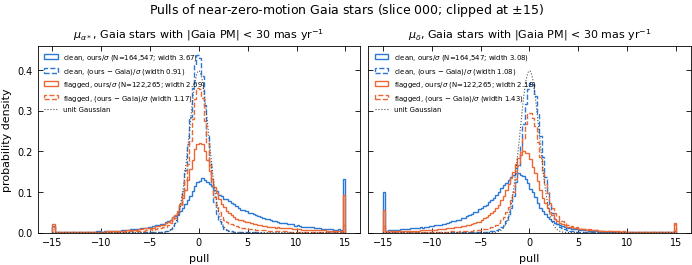

In [2]:
# 1. Pulls of Gaia stars with near-zero Gaia PM, clean vs flagged
T = pma.load_combined('gaia-objects', [DEGREE])
sel = pma.gaia_star_mask(T, clean=False)
clean = pma.clean_mask(T)
near0 = (np.abs(T.pmra) < 30) & (np.abs(T.pmdec) < 30)
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 2.7), sharex=True, sharey=True, constrained_layout=True)
xs = np.linspace(-15, 15, 300); gauss = np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi)
for ax, comp, name in [(axes[0], 'pmra', r'$\mu_{\alpha*}$'), (axes[1], 'pmdec', r'$\mu_\delta$')]:
    ours, gaia, ivar = T.get(comp + '_no_plx'), T.get(comp), T.get(comp + '_no_plx_ivar')
    for k, (s, label) in enumerate([(sel & near0 & clean, 'clean'), (sel & near0 & ~clean, 'flagged')]):
        p = ours[s] * np.sqrt(ivar[s]); d = (ours[s] - gaia[s]) * np.sqrt(ivar[s])
        ax.hist(np.clip(p, -15, 15), bins=120, range=(-15, 15), density=True, histtype='step', color=ps.SERIES[k],
                label=f'{label}, ours/$\\sigma$ (N={s.sum():,}; width {rs(p):.2f})')
        ax.hist(np.clip(d, -15, 15), bins=120, range=(-15, 15), density=True, histtype='step', ls='--', color=ps.SERIES[k],
                label=f'{label}, (ours $-$ Gaia)/$\\sigma$ (width {rs(d):.2f})')
    ax.plot(xs, gauss, color='0.3', lw=0.8, ls=':', label='unit Gaussian')
    ax.set_title(f'{name}, Gaia stars with |Gaia PM| < 30 mas yr$^{{-1}}$'); ax.set_xlabel('pull')
    ax.legend(fontsize=5, loc='upper left')
axes[0].set_ylabel('probability density')
fig.suptitle(f'Pulls of near-zero-motion Gaia stars (slice {DEGREE}; clipped at $\\pm$15)')
plt.savefig(OUT + 'pull_near_zero_gaia.pdf')

In [3]:
# 2. PM uncertainty vs magnitude: per-object errors from measured epochs, for a random sample of bricks
paths = sorted(glob.glob(f'/pscratch/sd/n/nelfalou/legacypm-catalogue-v2/{DEGREE}/tractor-pm-*.fits'))
paths = list(np.random.default_rng(0).choice(paths, min(N_BRICKS, len(paths)), replace=False))
TCOLS = ['objid', 'type', 'ref_cat', 'flux_r', 'flux_g', 'flux_i', 'maskbits', 'pmra', 'pmdec', 'pmra_ivar', 'pmdec_ivar',
         'pmra_no_plx', 'pmdec_no_plx', 'pm_flag']
rows = {k: [] for k in ['r', 'gaia', 'clean', 'gaia_sig_ra', 'gaia_sig_dec', 'stat_ra', 'stat_dec', 'real_ra', 'real_dec', 'd_ra', 'd_dec']}
for p in paths:
    A = fitsio.read(p, columns=TCOLS)
    F = fitsio.read(p.replace('tractor-pm-', 'forced-'), columns=['objid', 'mjd', 'filter', 'full_fit_dra', 'full_fit_dra_ivar', 'full_fit_ddec_ivar',
                                                                 'full_fit_dra_ivar_total', 'full_fit_ddec_ivar_total'])
    F = F[(F['full_fit_dra_ivar'] > 0) & (F['full_fit_ddec_ivar'] > 0) & (F['full_fit_dra'] != 0) & (F['objid'] < len(A))]
    o, n = F['objid'], len(A)
    t = (F['mjd'] - 51544.5) / 365.2425
    nep = np.bincount(o, minlength=n)
    tmin = np.full(n, np.inf); tmax = np.full(n, -np.inf); np.minimum.at(tmin, o, t); np.maximum.at(tmax, o, t)
    def sig_mu(var_mas2):
        w = 1 / var_mas2
        s0, s1, s2 = (np.bincount(o, w * t**k, minlength=n) for k in (0, 1, 2))
        with np.errstate(all='ignore'):
            return 1 / np.sqrt(s2 - s1**2 / s0)
    out = {}
    for ax, col in [('ra', 'full_fit_dra_ivar'), ('dec', 'full_fit_ddec_ivar')]:
        var = 1e6 / F[col]                                     # mas^2
        out['stat_' + ax] = sig_mu(var)
        out['real_' + ax] = sig_mu(1e6 / F[col.replace('_ivar', '_ivar_total')])   # the pipeline's total error (error_model.py)
    psf = np.char.strip(A['type'].astype(str)) == 'PSF'
    gaia = np.char.strip(A['ref_cat'].astype(str)) == 'GE'
    mb = A['maskbits'].astype(np.int64)
    clean = (psf & (A['pm_flag'] == 1) & (nep >= 10) & ((tmax - tmin) * 365.2425 >= 730) & (A['flux_g'] > 0) & (A['flux_i'] > 0)
             & ((mb & ((1 << 1) | (1 << 11) | (1 << 2) | (1 << 3) | (1 << 4) | (1 << 14))) == 0))
    with np.errstate(all='ignore'):
        rows['r'].append(22.5 - 2.5 * np.log10(A['flux_r']))
    rows['gaia'].append(gaia & (A['pmra_ivar'] > 0) & (A['pmdec_ivar'] > 0)); rows['clean'].append(clean)
    rows['gaia_sig_ra'].append(np.where(A['pmra_ivar'] > 0, 1 / np.sqrt(np.where(A['pmra_ivar'] > 0, A['pmra_ivar'], 1)), np.nan))
    rows['gaia_sig_dec'].append(np.where(A['pmdec_ivar'] > 0, 1 / np.sqrt(np.where(A['pmdec_ivar'] > 0, A['pmdec_ivar'], 1)), np.nan))
    for k in ('stat_ra', 'stat_dec', 'real_ra', 'real_dec'):
        rows[k].append(out[k])
    rows['d_ra'].append(A['pmra_no_plx'] - A['pmra']); rows['d_dec'].append(A['pmdec_no_plx'] - A['pmdec'])
R = {k: np.concatenate(v) for k, v in rows.items()}
print(f"{len(paths)} bricks: {R['clean'].sum():,} clean PSF objects, {R['gaia'].sum():,} Gaia stars with a Gaia PM, "
      f"{(R['gaia'] & R['clean']).sum():,} both")

100 bricks: 185,335 clean PSF objects, 21,409 Gaia stars with a Gaia PM, 9,061 both


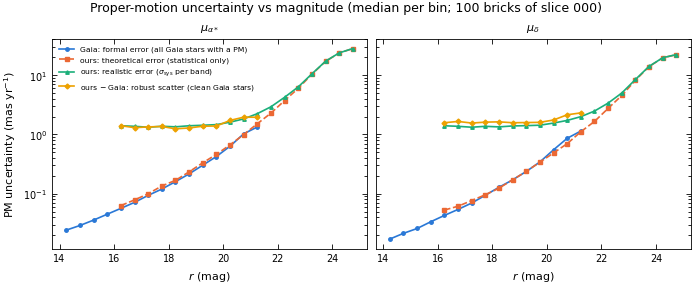

In [4]:
mb = np.arange(14, 25.01, 0.5); mc = 0.5 * (mb[1:] + mb[:-1])
def binned(stat, val, sel):
    out = []
    for a, b in zip(mb, mb[1:]):
        v = val[sel & (R['r'] > a) & (R['r'] <= b) & np.isfinite(val)]
        out.append(stat(v) if len(v) >= 50 else np.nan)
    return np.array(out)
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 2.9), sharex=True, sharey=True, constrained_layout=True)
for ax, comp, name in [(axes[0], 'ra', r'$\mu_{\alpha*}$'), (axes[1], 'dec', r'$\mu_\delta$')]:
    lines = [('Gaia: formal error (all Gaia stars with a PM)', binned(np.median, R['gaia_sig_' + comp], R['gaia']), '-'),
             ('ours: theoretical error (statistical only)', binned(np.median, R['stat_' + comp], R['clean']), '--'),
             (r'ours: realistic error (error model)', binned(np.median, R['real_' + comp], R['clean']), '-'),
             ('ours $-$ Gaia: robust scatter (clean Gaia stars)', binned(rs, R['d_' + comp], R['clean'] & R['gaia']), '-')]
    for k, (label, y, ls) in enumerate(lines):
        ax.semilogy(mc, y, ls=ls, marker=ps.MARKERS[k], ms=2.5, color=ps.SERIES[k], label=label)
    ax.set_title(name); ax.set_xlabel('$r$ (mag)')
axes[0].set_ylabel('PM uncertainty (mas yr$^{-1}$)'); axes[0].legend(fontsize=5.5, loc='upper left')
fig.suptitle(f'Proper-motion uncertainty vs magnitude (median per bin; {len(paths)} bricks of slice {DEGREE})')
plt.savefig(PLOTS + 'pm_errors_vs_mag.pdf')